# 06 — Transformer encoder

**Purpose.** Train a small causal Transformer on the same 24-hour windows.

**Inputs.** Sequence arrays from notebook 02.

**Outputs.** `models/transformer.pt`, `results/predictions_transformer.csv`, `results/tables/metrics_transformer.csv`.


In [1]:
# Shared deep-learning setup: frozen splits, GPU if available, one global seed.
from pathlib import Path
import os, sys, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

PROJECT_ROOT = Path.cwd().parent
os.environ["MPLCONFIGDIR"] = str(PROJECT_ROOT / ".mplconfig")
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import (
    SEED, set_seed, print_library_versions, ensure_dirs, save_fig,
    get_torch_device, WindowSequenceDataset, load_sequence_split,
    downsample_indices, predict_torch_model, count_parameters, file_size_mb,
    classification_metrics, choose_threshold_max_f1, early_detection_metrics,
    metrics_to_row, save_metrics_table, save_predictions,
    plot_confusion_heatmap, plot_roc_pr,
    permutation_importance_torch, time_step_importance_torch,
)
from src.torch_models import TransformerClassifier, train_sequence_model

set_seed(SEED)
print("SEED =", SEED)
print_library_versions()
PATHS = ensure_dirs(PROJECT_ROOT)
DEVICE = get_torch_device()
WINDOW = json.load(open(PATHS["processed"] / "sequence_config.json"))["window"]
print("WINDOW", WINDOW)


SEED = 42
python 3.9.6 (default, Oct 19 2026, 19:18:13)  [Clang 21.0.0 (clang-2100.4.1.1)]
numpy        2.0.2
pandas       2.3.3
sklearn      1.6.1
xgboost      2.1.4
torch        2.8.0
shap         0.49.1
optuna       5.0.0
matplotlib   3.9.4
seaborn      0.13.2
Using device: cpu
WINDOW 24


## Model-specific EDA: positional encoding and attention cost


window T = 24 d_model = 64 heads = 4
self-attention cost per layer is O(T^2 * d) = 36864
At T=24 this is cheap; at T=512 it would dominate. That is why we keep a 24-hour window.


/Users/shaikniyaz/projects/CSET343_project/notebooks/06_model_transformer.ipynb:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "source": [


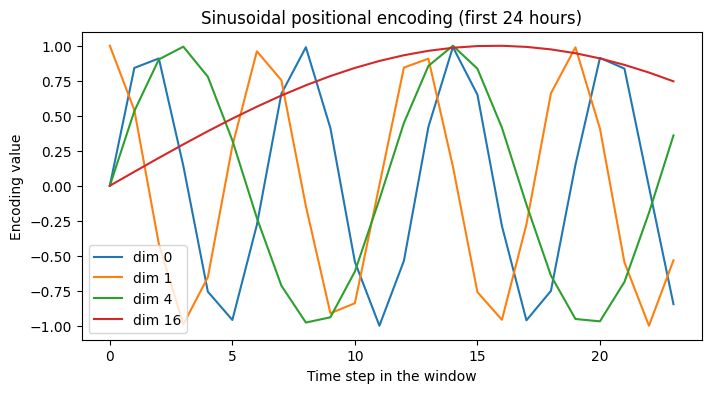

In [2]:
# Transformers do not know order unless we add a position signal. Attention cost grows with T^2.
WINDOW = json.load(open(PATHS["processed"] / "sequence_config.json"))["window"]
d_model = 64
n_heads = 4
print("window T =", WINDOW, "d_model =", d_model, "heads =", n_heads)
print("self-attention cost per layer is O(T^2 * d) =", WINDOW * WINDOW * d_model)
print("At T=24 this is cheap; at T=512 it would dominate. That is why we keep a 24-hour window.")

# Show the sine/cosine clocks for a few dimensions.
pos = np.arange(WINDOW)[:, None]
div = np.exp(np.arange(0, d_model, 2) * (-np.log(10000.0) / d_model))
pe = np.zeros((WINDOW, d_model))
pe[:, 0::2] = np.sin(pos * div)
pe[:, 1::2] = np.cos(pos * div)
fig, ax = plt.subplots(figsize=(8, 4))
for dim in [0, 1, 4, 16]:
    ax.plot(np.arange(WINDOW), pe[:, dim], label=f"dim {dim}")
ax.set_title("Sinusoidal positional encoding (first 24 hours)")
ax.set_xlabel("Time step in the window")
ax.set_ylabel("Encoding value")
ax.legend()
save_fig(fig, PATHS["figures"] / "06_positional_encoding.png")
plt.show()


**What we learned.** Positional encodings give each hour a unique pattern so attention can tell '3 hours ago' from '20 hours ago'. A causal mask then blocks looking into the future inside the window.


In [3]:
# Load sequence arrays. Train uses the documented patient subsample + negative downsampling; val/test stay natural.
dl = load_sequence_split(PATHS["sequences"], "dl_train")
val = load_sequence_split(PATHS["sequences"], "val")
test = load_sequence_split(PATHS["sequences"], "test")
feat_names = json.load(open(PATHS["processed"] / "sequence_feature_cols.json"))
print("features", len(feat_names), feat_names[:8], "...")

# Downsample validation *only* for the per-epoch monitor so early stopping is fast.
# Threshold selection later uses the full validation set.
rng = np.random.default_rng(SEED)
val_mon_idx = downsample_indices(val["y"], max_neg_per_pos=6.0, seed=SEED)
train_idx = downsample_indices(dl["y"], max_neg_per_pos=8.0, seed=SEED)
print("train windows used", len(train_idx), "pos_rate", dl["y"][train_idx].mean())
print("val monitor windows", len(val_mon_idx), "full val", len(val["y"]))

train_ds = WindowSequenceDataset(dl["X"], dl["y"], dl["patient_start"], dl["patient_id"], dl["hour"], WINDOW, train_idx)
val_mon_ds = WindowSequenceDataset(val["X"], val["y"], val["patient_start"], val["patient_id"], val["hour"], WINDOW, val_mon_idx)
val_ds = WindowSequenceDataset(val["X"], val["y"], val["patient_start"], val["patient_id"], val["hour"], WINDOW)
test_ds = WindowSequenceDataset(test["X"], test["y"], test["patient_start"], test["patient_id"], test["hour"], WINDOW)

n_pos = float((dl["y"][train_idx] == 1).sum())
n_neg = float((dl["y"][train_idx] == 0).sum())
pos_weight = n_neg / max(n_pos, 1.0)
print("BCE pos_weight", round(pos_weight, 3))
n_features = dl["X"].shape[1]
print("n_features", n_features)


features 72 ['HR', 'O2Sat', 'Temp', 'SBP', 'MAP', 'DBP', 'Resp', 'BaseExcess'] ...
train windows used 30159 pos_rate 0.11111111
val monitor windows 12481 full val 82478
BCE pos_weight 8.0
n_features 72


## Architecture


In [4]:
# input projection -> sinusoidal PE -> 2 encoder layers (4 heads, d_model=64) with causal + padding masks -> last token.
model = TransformerClassifier(n_features=n_features, d_model=64, n_heads=4, n_layers=2, dropout=0.3, max_len=WINDOW)
print(model)
print("parameters", count_parameters(model))


TransformerClassifier(
  (input_proj): Linear(in_features=72, out_features=64, bias=True)
  (pos): SinusoidalPositionalEncoding()
  (encoder): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=256, bias=True)
        (dropout): Dropout(p=0.3, inplace=False)
        (linear2): Linear(in_features=256, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.3, inplace=False)
        (dropout2): Dropout(p=0.3, inplace=False)
      )
    )
  )
  (drop): Dropout(p=0.3, inplace=False)
  (head): Linear(in_features=64, out_features=1, bias=True)
)
parameters 104705


## Train


epoch 01  train_loss=1.0466  val_loss=1.2498  val_pr_auc=0.3930
epoch 02  train_loss=0.9405  val_loss=1.3472  val_pr_auc=0.3758
epoch 03  train_loss=0.8903  val_loss=1.5443  val_pr_auc=0.3710
epoch 04  train_loss=0.8237  val_loss=1.6445  val_pr_auc=0.3078
Early stopping at epoch 4 (best val PR-AUC=0.3930)


/Users/shaikniyaz/projects/CSET343_project/notebooks/06_model_transformer.ipynb:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "execution_count": null,


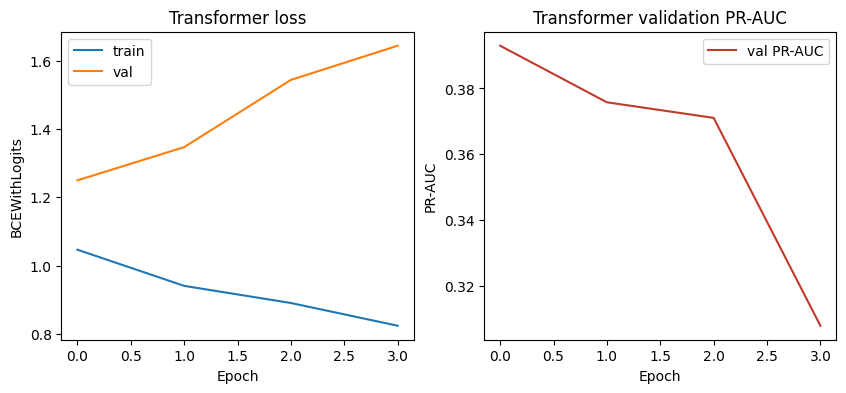

In [5]:
history = train_sequence_model(
    model, train_ds, val_mon_ds, DEVICE,
    pos_weight=pos_weight, epochs=10, patience=3, lr=1e-3, batch_size=128,
    ckpt_path=PATHS["models"] / "transformer_best.pt",
)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_title("Transformer loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCEWithLogits")
axes[0].legend()
axes[1].plot(history["val_pr_auc"], label="val PR-AUC", color="#c0392b")
axes[1].set_title("Transformer validation PR-AUC")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("PR-AUC")
axes[1].legend()
save_fig(fig, PATHS["figures"] / "06_transformer_curves.png")
plt.show()


## Threshold, test evaluation, save


threshold 0.9 val F1 0.1745 val PR-AUC 0.0923
{'roc_auc': 0.7569, 'pr_auc': 0.0848, 'precision': 0.1491, 'recall': 0.1933, 'f1': 0.1684, 'specificity': 0.9753, 'accuracy': 0.9582, 'brier': 0.2096, 'threshold': 0.9, 'tp': 343, 'fp': 1957, 'tn': 77252, 'fn': 1431, 'n': 80983, 'n_positive': 1774}
early detection {'n_sepsis_patients': 186, 'pct_detected': 24.193548387096776, 'pct_detected_6h_before': 17.741935483870968, 'edt_mean_hours': 40.31111111111111, 'edt_median_hours': 25.0, 'false_alarms_per_patient_day': 0.592962920880203, 'n_detected': 45}
saved /Users/shaikniyaz/projects/CSET343_project/models/transformer.pt


/Users/shaikniyaz/projects/CSET343_project/notebooks/06_model_transformer.ipynb:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "cell_type": "code",
/Users/shaikniyaz/projects/CSET343_project/notebooks/06_model_transformer.ipynb:20: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "id": "9dbc7589",


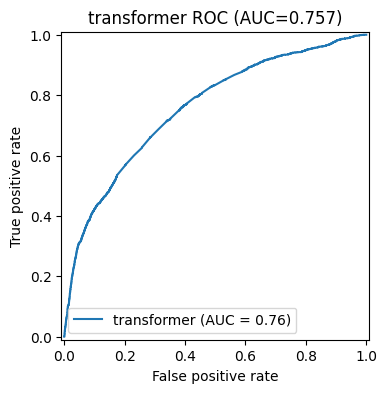

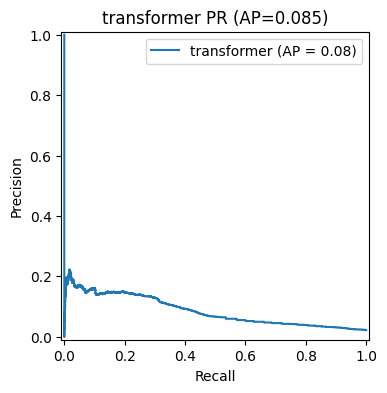

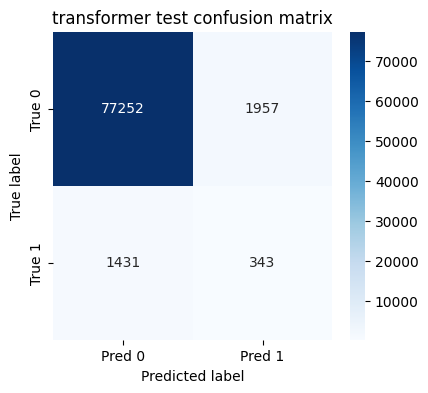

In [6]:
# Freeze the F1-max threshold on FULL validation, then score test patients only once.
p_va = predict_torch_model(model, val_ds, DEVICE, batch_size=256)
thr, val_m = choose_threshold_max_f1(val["y"], p_va)
print("threshold", round(thr, 4), "val F1", round(val_m["f1"], 4), "val PR-AUC", round(val_m["pr_auc"], 4))

t1 = time.time()
p_te = predict_torch_model(model, test_ds, DEVICE, batch_size=256)
infer_seconds = time.time() - t1
metrics = classification_metrics(test["y"], p_te, thr)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in metrics.items()})

pred_path = PATHS["results"] / "predictions_transformer.csv"
save_predictions(test["patient_id"], test["hour"], test["y"], p_te, pred_path)
edt, _ = early_detection_metrics(pd.read_csv(pred_path), "patient_id", "hour", threshold=thr)
print("early detection", edt)

plot_roc_pr(test["y"], p_te, "transformer", PATHS["figures"] / "06_transformer_roc.png", PATHS["figures"] / "06_transformer_pr.png")
plt.show()
plot_confusion_heatmap(metrics, "transformer test confusion matrix", PATHS["figures"] / "06_transformer_cm.png")
plt.show()

ckpt = PATHS["models"] / "transformer.pt"
torch.save({"state_dict": model.state_dict(), "threshold": thr, "n_features": n_features, "window": WINDOW}, ckpt)
extra = dict(
    train_seconds=history["train_seconds"], infer_seconds=infer_seconds,
    n_params=count_parameters(model), model_mb=file_size_mb(ckpt),
    **{f"edt_{k}": v for k, v in edt.items() if k != "n_sepsis_patients"},
    n_sepsis_patients=edt["n_sepsis_patients"],
)
save_metrics_table(metrics_to_row("transformer", metrics, extra), PATHS["tables"] / "metrics_transformer.csv")
print("saved", ckpt)


## Attention heatmap and feature importance


patient 373 hour 139 prob later from saved file


/Users/shaikniyaz/projects/CSET343_project/notebooks/06_model_transformer.ipynb:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "    downsample_indices, predict_torch_model, count_parameters, file_size_mb,\n",


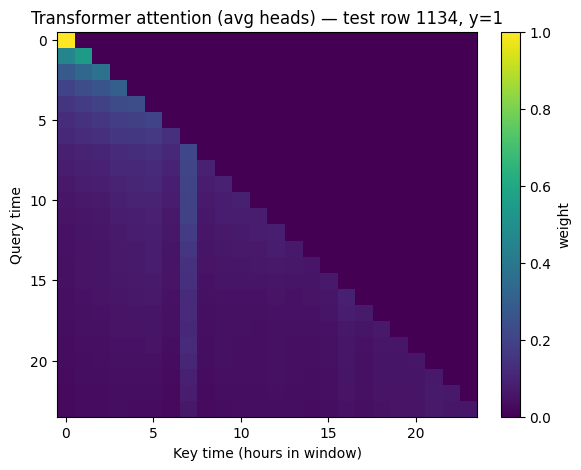

In [7]:
# Attention weights for one septic test window, plus the same permutation fallback as the other deep models.
from torch.utils.data import DataLoader

# Find a sepsis-positive test index with enough history if possible.
pos_idx = np.where(test["y"] == 1)[0]
show_i = int(pos_idx[0]) if len(pos_idx) else 0
one = WindowSequenceDataset(test["X"], test["y"], test["patient_start"], test["patient_id"], test["hour"], WINDOW, np.array([show_i]))
seq, mask, y, row = one[0]
seq_b, mask_b = seq.unsqueeze(0).to(DEVICE), mask.unsqueeze(0).to(DEVICE)

# Recreate attention from the first encoder layer by a manual capture.
attn_w = []
def hook(mod, inp, out):
    # TransformerEncoderLayer does not return weights; use a small manual attention on projected tokens instead.
    pass

model.eval()
with torch.no_grad():
    h = model.pos(model.input_proj(seq_b))
    # Grab QK^T from layer 0 self attention
    layer = model.encoder.layers[0]
    x = h
    # PyTorch MHA: use the module directly
    attn_mod = layer.self_attn
    t = x.size(1)
    causal = torch.triu(torch.ones(t, t, dtype=torch.bool, device=DEVICE), 1)
    pad = (mask_b == 0)
    _, w = attn_mod(x, x, x, attn_mask=causal, need_weights=True, average_attn_weights=True)
    # w: (batch, T, T)
    W = w[0].cpu().numpy()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(W, cmap="viridis", aspect="auto")
ax.set_title(f"Transformer attention (avg heads) — test row {show_i}, y={int(y.item())}")
ax.set_xlabel("Key time (hours in window)")
ax.set_ylabel("Query time")
fig.colorbar(im, ax=ax, fraction=0.046, label="weight")
save_fig(fig, PATHS["figures"] / "06_attention_heatmap.png")
plt.show()
print("patient", int(test["patient_id"][show_i]), "hour", int(test["hour"][show_i]), "prob later from saved file")


baseline PR-AUC on SHAP/permutation sample: 0.1977
      feature  pr_auc_drop
       ICULOS     0.152853
          Age     0.026216
           HR     0.019850
 AST_measured     0.010787
Temp_measured     0.009742
      Calcium     0.007753
          BUN     0.007086
    Potassium     0.006876
          Hgb     0.004526
FiO2_measured     0.003202
 Alkalinephos     0.002589
    Platelets     0.001467
SHAP GradientExplainer not used (unstable or failed). Fallback = permutation importance.
reason: IndexError too many indices for tensor of dimension 1


/Users/shaikniyaz/projects/CSET343_project/notebooks/06_model_transformer.ipynb:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "**Outputs.** `models/transformer.pt`, `results/predictions_transformer.csv`, `results/tables/metrics_transformer.csv`.\n"
/Users/shaikniyaz/projects/CSET343_project/notebooks/06_model_transformer.ipynb:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  "# Shared deep-learning setup: frozen splits, GPU if available, one global seed.\n",


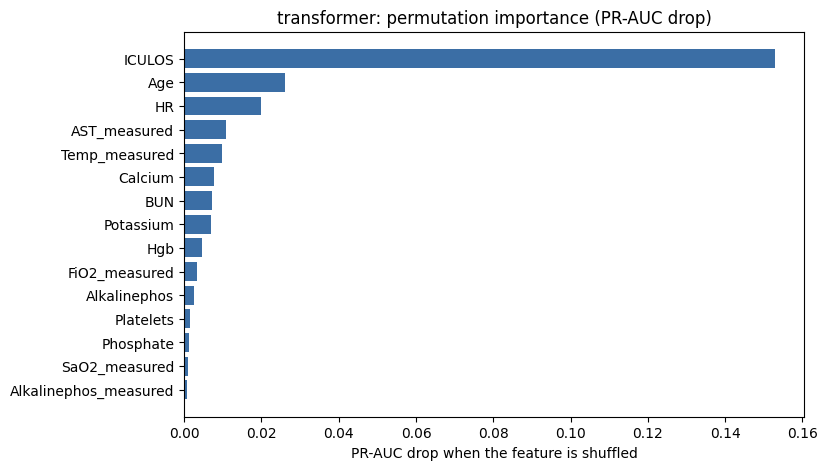

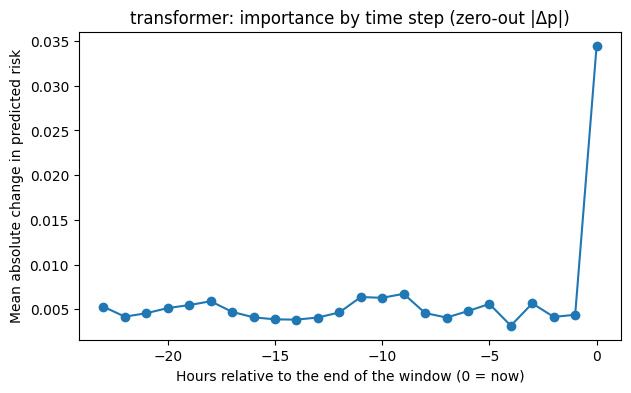

In [8]:
# Explainability: try a small SHAP GradientExplainer; if it fails or looks unstable, fall back to permutation importance.
# We also measure which hours in the 24-hour window move the prediction the most.
from sklearn.metrics import average_precision_score

imp_df, base_ap = permutation_importance_torch(model, test_ds, DEVICE, feat_names, n_samples=350, seed=SEED)
print("baseline PR-AUC on SHAP/permutation sample:", round(base_ap, 4))
print(imp_df.head(12).to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 5))
top = imp_df.head(15).iloc[::-1]
ax.barh(top["feature"], top["pr_auc_drop"], color="#3b6ea5")
ax.set_title("transformer: permutation importance (PR-AUC drop)")
ax.set_xlabel("PR-AUC drop when the feature is shuffled")
save_fig(fig, PATHS["figures"] / "06_transformer_perm_importance.png")
plt.show()

impact = time_step_importance_torch(model, test_ds, DEVICE, n_samples=350, seed=SEED)
fig, ax = plt.subplots(figsize=(7, 4))
hours_before = np.arange(-WINDOW + 1, 1)
ax.plot(hours_before, impact, marker="o")
ax.set_title("transformer: importance by time step (zero-out |Δp|)")
ax.set_xlabel("Hours relative to the end of the window (0 = now)")
ax.set_ylabel("Mean absolute change in predicted risk")
save_fig(fig, PATHS["figures"] / "06_transformer_time_importance.png")
plt.show()

# Optional SHAP on a tiny batch; skip cleanly if the explainer errors.
try:
    import shap
    from torch.utils.data import DataLoader
    bg_n = 32
    ex_n = 48
    bg_loader = DataLoader(WindowSequenceDataset(dl["X"], dl["y"], dl["patient_start"], dl["patient_id"], dl["hour"], WINDOW, train_idx[:bg_n]), batch_size=bg_n)
    ex_loader = DataLoader(WindowSequenceDataset(test["X"], test["y"], test["patient_start"], test["patient_id"], test["hour"], WINDOW, np.arange(ex_n)), batch_size=ex_n)
    bg_seq, bg_mask, _, _ = next(iter(bg_loader))
    ex_seq, ex_mask, _, _ = next(iter(ex_loader))
    # Flatten time*feature so GradientExplainer sees a 2D tensor, then wrap the model.
    class FlatWrap(torch.nn.Module):
        def __init__(self, m, t, f, mask):
            super().__init__()
            self.m, self.t, self.f, self.mask = m, t, f, mask
        def forward(self, z):
            x = z.view(-1, self.t, self.f)
            return self.m(x, self.mask.to(z.device)[:x.size(0)] if self.mask.size(0)==x.size(0) else self.mask[:1].repeat(x.size(0),1))
    model.eval()
    wrap = FlatWrap(model, WINDOW, n_features, ex_mask.to(DEVICE)).to(DEVICE)
    explainer = shap.GradientExplainer(wrap, bg_seq.to(DEVICE).reshape(bg_n, -1))
    sv = explainer.shap_values(ex_seq.to(DEVICE).reshape(ex_n, -1))
    sv = np.array(sv).reshape(ex_n, WINDOW, n_features)
    mean_abs = np.abs(sv).mean(axis=(0, 1))
    order = np.argsort(mean_abs)[-15:]
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.barh([feat_names[i] for i in order], mean_abs[order], color="#3b6ea5")
    ax.set_title("transformer: mean |SHAP| aggregated over time")
    ax.set_xlabel("mean |SHAP|")
    save_fig(fig, PATHS["figures"] / "06_transformer_shap_bar.png")
    plt.show()
    print("SHAP GradientExplainer succeeded on a small sample.")
except Exception as e:
    print("SHAP GradientExplainer not used (unstable or failed). Fallback = permutation importance.")
    print("reason:", type(e).__name__, str(e)[:300])


### Notebook 06 summary


In [9]:
print(pd.read_csv(PATHS["tables"] / "metrics_transformer.csv").T)
print("Done with notebook 06.")


                                            0
model                             transformer
roc_auc                              0.756947
pr_auc                               0.084772
precision                             0.14913
recall                               0.193348
f1                                   0.168385
specificity                          0.975293
accuracy                             0.958164
brier                                0.209554
threshold                                 0.9
tp                                        343
fp                                       1957
tn                                      77252
fn                                       1431
n                                       80983
n_positive                               1774
train_seconds                       22.078232
infer_seconds                        3.341869
n_params                               104705
model_mb                                0.415
edt_pct_detected                  